# 01 — MLP baseline

A fully connected network on raw 128x128 pixels, compared with a majority-class baseline and a decision tree on image metadata.
Two scopes are trained from scratch: Photo vs Text only, and the full dataset (Photo vs the 4 other origins).

In [1]:
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import keras
from sklearn.metrics import balanced_accuracy_score
from sklearn.tree import DecisionTreeClassifier
from utils import CACHE, METRICS, class_weights, evaluate, load_images

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", gpus)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

REPORTS = Path("reports")
CACHE.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
SEED, SIZE, EPOCHS, BATCH = 42, 128, 15, 32

I0000 00:00:1791483039.089906    7979 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791483039.784822    7979 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
manifest = pd.read_csv("protocol/manifest.csv")
df = manifest[manifest["drop_reason"].isna()].reset_index(drop=True)
counts = pd.crosstab(df["origin"], df["split"], margins=True, margins_name="total")
print(counts[["train", "val", "test", "total"]])
test = df[df["split"] == "test"]
photo_share = (test["label"] == 1).mean()
print(f"\nPhoto share in test: {photo_share:.4f} -> majority-class accuracy: {1 - photo_share:.4f}")

split       train   val  test  total
origin                              
Painting     6997  1499  1500   9996
Photo        6995  1499  1499   9993
Schematics   6236  1336  1336   8908
Sketch        984   211   211   1406
Text         6999  1500  1500   9999
total       28211  6045  6046  40302

Photo share in test: 0.2479 -> majority-class accuracy: 0.7521


## Helpers

Images are resized to 128x128 without keeping the aspect ratio and converted to RGB (grayscale, palette and CMYK files included).
Class weights are computed on the training rows only, so validation and test stay untouched.

In [5]:
t = time.time()
splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X = {s: load_images(d, SIZE) for s, d in splits.items()}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype, f"{X[s].nbytes / 1e9:.2f} GB")
print(f"Loaded in {time.time() - t:.0f} s")

train (28211, 128, 128, 3) uint8 1.39 GB
val (6045, 128, 128, 3) uint8 0.30 GB
test (6046, 128, 128, 3) uint8 0.30 GB
Loaded in 3 s


## Baselines (full test set)

The majority class always predicts non-Photo, so its Photo precision, recall and F1 are 0 and its PR-AUC equals the Photo share.
The decision tree uses only width, height, aspect ratio and colour mode; its depth is chosen on validation balanced accuracy.

In [6]:
baselines = {"majority": evaluate(y["test"], np.zeros(len(y["test"])), splits["test"]["origin"])}

def meta_features(d):
    f = pd.DataFrame({"width": d["width"], "height": d["height"], "ratio": d["width"] / d["height"]})
    for m in sorted(df["mode"].unique()):
        f[f"mode_{m}"] = (d["mode"] == m).astype(int)
    return f

F = {s: meta_features(d) for s, d in splits.items()}
cw_full = class_weights(y["train"])
val_bacc = {}
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=cw_full, random_state=42).fit(F["train"], y["train"])
    val_bacc[depth] = balanced_accuracy_score(y["val"], tree.predict(F["val"]))
best_depth = max(val_bacc, key=val_bacc.get)
print("Validation balanced accuracy by depth:", {k: round(v, 4) for k, v in val_bacc.items()})
print("Selected depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw_full, random_state=42).fit(F["train"], y["train"])
baselines["decision_tree_meta"] = evaluate(y["test"], tree.predict_proba(F["test"])[:, 1], splits["test"]["origin"])
pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in baselines.items()}).T.round(4)

Validation balanced accuracy by depth: {1: 0.8165, 2: 0.8718, 3: 0.9216, 4: 0.9256, 5: 0.9256, 6: 0.9711, 7: 0.9817, 8: 0.983, 9: 0.982, 10: 0.9835, 11: 0.9835, 12: 0.9832}
Selected depth: 10


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


What I observe

Observed:
- The metadata tree (width, height, ratio, mode) is almost perfect on test, far above the majority class.

Meaning: image format alone nearly separates Photo from the other origins, so the tree is the real bar for any pixel model.

Dense(128) holds almost all weights: 49,152 × 128 + 128 = 6,291,584 of the 6,299,905 parameters.
Binary cross-entropy is used with class_weight so that both classes weigh the same in total; Adam uses its default learning rate of 1e-3.

In [7]:
def build_mlp(seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input((SIZE, SIZE, 3)),
        keras.layers.Rescaling(1 / 255),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

build_mlp(42).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,299,905 (24.03 MB)

 Trainable params: 6,299,905 (24.03 MB)

 Non-trainable params: 0 (0.00 B)

## Training: two scopes, seed 42

Each scope is trained from scratch for 15 epochs and the last-epoch weights are kept; nothing is tuned on test.
Test predictions are stored here but only reported in the Results section.

In [8]:
SCOPES = {"photo_vs_text": ["Photo", "Text"], "full": sorted(df["origin"].unique())}
mask = {(sc, s): splits[s]["origin"].isin(o).to_numpy() for sc, o in SCOPES.items() for s in splits}

def run_scope(scope, seed=SEED):
    tr, va, te = mask[(scope, "train")], mask[(scope, "val")], mask[(scope, "test")]
    model = build_mlp(seed)
    t = time.time()
    hist = model.fit(X["train"][tr], y["train"][tr], validation_data=(X["val"][va], y["val"][va]),
                     epochs=EPOCHS, batch_size=BATCH, class_weight=class_weights(y["train"][tr]), verbose=0)
    out = {"history": hist.history, "time_s": time.time() - t,
           "val": evaluate(y["val"][va], model.predict(X["val"][va], verbose=0), splits["val"]["origin"][va]),
           "proba_test": model.predict(X["test"], verbose=0).ravel()}  # full test set, subset later
    keras.backend.clear_session()
    return out

runs = {}
for scope in SCOPES:
    runs[scope] = r = run_scope(scope)
    print(f"{scope:14s}: {r['time_s']:.0f} s | val balanced acc {r['val']['balanced_acc']:.4f}")

photo_vs_text : 39 s | val balanced acc 0.9883


full          : 57 s | val balanced acc 0.8079


In [9]:
pd.DataFrame({sc: {m: runs[sc]["val"][m] for m in METRICS} for sc in SCOPES}).T.round(4)

,precision,recall,f1,balanced_acc,pr_auc,accuracy
photo_vs_text,0.9966,0.9800,0.9882,0.9883,0.9998,0.9883
full,0.5104,0.9006,0.6515,0.8079,0.6033,0.7611


What I observe

Observed:
- Validation balanced accuracy is 0.9883 for Photo vs Text and 0.8079 for the full scope, about 18 points lower.

Meaning: separating Photo from four origins is much harder for the MLP than separating it from Text alone.

## Learning curves

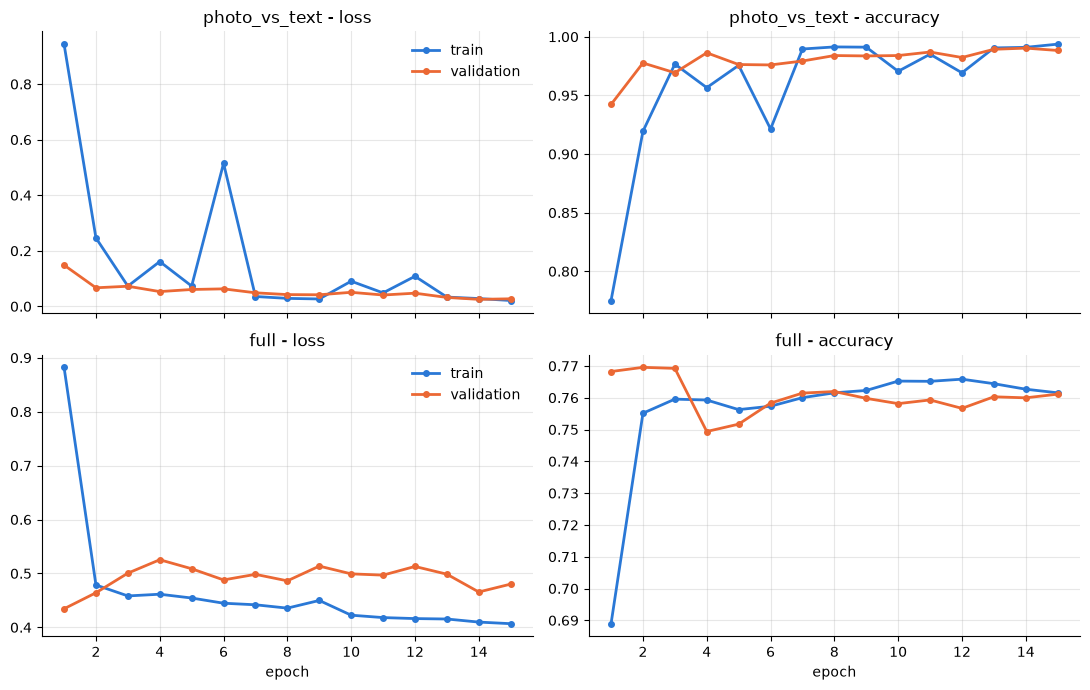

Last epoch (15) unless stated otherwise


,loss,val_loss,accuracy,val_accuracy,min val_accuracy,max val_accuracy,epoch of max val_accuracy
photo_vs_text,0.0211,0.0273,0.9937,0.9883,0.9423,0.9903,14.0
full,0.4068,0.4802,0.7615,0.7611,0.7494,0.7696,2.0


In [10]:
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
epochs = np.arange(1, EPOCHS + 1)
for i, scope in enumerate(SCOPES):
    h = runs[scope]["history"]
    for j, m in enumerate(["loss", "accuracy"]):
        ax = axes[i, j]
        ax.plot(epochs, h[m], color=C_TRAIN, lw=2, marker="o", ms=4, label="train")
        ax.plot(epochs, h[f"val_{m}"], color=C_VAL, lw=2, marker="o", ms=4, label="validation")
        ax.set_title(f"{scope} - {m}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[i, 0].legend(frameon=False)
for ax in axes[1]:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_curves.png", dpi=120)
plt.show()

rows = {}
for sc, r in runs.items():
    h = r["history"]
    rows[sc] = {"loss": h["loss"][-1], "val_loss": h["val_loss"][-1],
                "accuracy": h["accuracy"][-1], "val_accuracy": h["val_accuracy"][-1],
                "min val_accuracy": min(h["val_accuracy"]), "max val_accuracy": max(h["val_accuracy"]),
                "epoch of max val_accuracy": int(np.argmax(h["val_accuracy"])) + 1}
print(f"Last epoch ({EPOCHS}) unless stated otherwise")
pd.DataFrame(rows).T.round(4)

What I observe

Observed:
- Full scope: validation accuracy stays between 0.7494 and 0.7696 (maximum at epoch 2) and ends at 0.7611; train accuracy ends at 0.7615.

Train loss is class-weighted, validation loss is not: the two are not comparable.

Interpretation: the full-scope MLP gains little in validation accuracy after epoch 2.

## Results on the test set

Test metrics are computed once here, at threshold 0.5, on the natural test distribution of each scope.

In [11]:
test_eval = {sc: evaluate(y["test"][mask[(sc, "test")]], r["proba_test"][mask[(sc, "test")]],
                          splits["test"]["origin"][mask[(sc, "test")]]) for sc, r in runs.items()}
pt = mask[("photo_vs_text", "test")]
pt_full_model = evaluate(y["test"][pt], runs["full"]["proba_test"][pt], splits["test"]["origin"][pt])

table_full = pd.DataFrame({k: {m: f"{v[m]:.4f}" for m in METRICS} for k, v in baselines.items()}).T
table_full.loc["mlp (seed 42)"] = {m: f"{test_eval['full'][m]:.4f}" for m in METRICS}
table_full.drop("majority").rename_axis("model").to_csv(REPORTS / "test_results.csv")  # shared with later notebooks
print("Full scope, test set (n = %d)" % len(y["test"]))
display(table_full)

table_pt = pd.DataFrame({"mlp trained on photo_vs_text": {m: test_eval["photo_vs_text"][m] for m in METRICS},
                         "mlp trained on full scope": {m: pt_full_model[m] for m in METRICS}}).T.round(4)
print("Photo + Text test rows only (n = %d)" % pt.sum())
display(table_pt)

Full scope, test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
mlp (seed 42),0.4980,0.8953,0.6400,0.7989,0.6164,0.7502


Photo + Text test rows only (n = 2999)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
mlp trained on photo_vs_text,0.9993,0.9780,0.9885,0.9887,0.9999,0.9887
mlp trained on full scope,1.0000,0.8953,0.9447,0.9476,0.9999,0.9476


In [12]:
cols = ["balanced_acc", "f1", "accuracy"]
for name, b in baselines.items():
    d = 100 * (pd.Series({m: test_eval["full"][m] for m in cols}) - pd.Series({m: b[m] for m in cols}))
    print(f"MLP - {name} (points):", d.round(2).to_dict())

MLP - majority (points): {'balanced_acc': 29.89, 'f1': 64.0, 'accuracy': -0.18}
MLP - decision_tree_meta (points): {'balanced_acc': -18.78, 'f1': -33.46, 'accuracy': -23.7}


MLP full scope: [[TN FP] [FN TP]] = [[3194, 1353], [157, 1342]]
decision_tree_meta: [[TN FP] [FN TP]] = [[4492, 55], [22, 1477]]


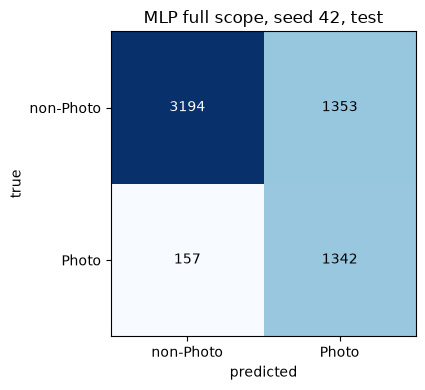

In [13]:
print("MLP full scope: [[TN FP] [FN TP]] =", test_eval["full"]["cm"].tolist())
print("decision_tree_meta: [[TN FP] [FN TP]] =", baselines["decision_tree_meta"]["cm"].tolist())

cm = test_eval["full"]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("MLP full scope, seed 42, test")
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_confusion.png", dpi=120)
plt.show()

            majority  decision_tree_meta     mlp
Painting         0.0              0.0320  0.7020
Photo            1.0              0.0147  0.1047
Schematics       0.0              0.0052  0.2246
Sketch           0.0              0.0000  0.0000
Text             0.0              0.0000  0.0000


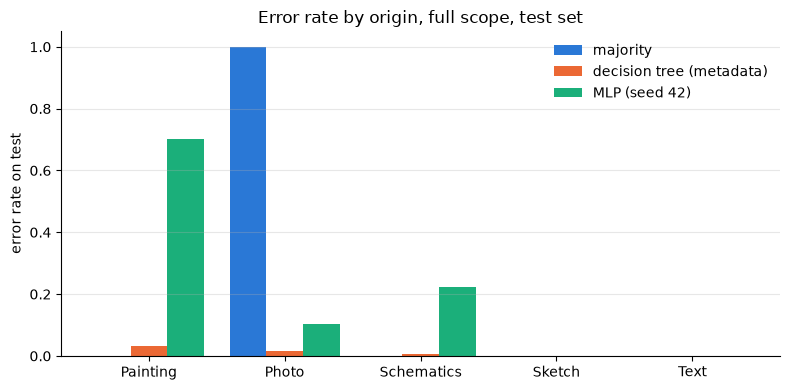

Total notebook runtime: 1.8 min


In [14]:
err = pd.DataFrame({"majority": baselines["majority"]["error_by_origin"],
                    "decision_tree_meta": baselines["decision_tree_meta"]["error_by_origin"],
                    "mlp": test_eval["full"]["error_by_origin"]})
print(err.round(4))

origins, w = list(err.index), 0.27
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(origins))
ax.bar(x - w, err["majority"], w, color="#2a78d6", label="majority")
ax.bar(x, err["decision_tree_meta"], w, color="#eb6834", label="decision tree (metadata)")
ax.bar(x + w, err["mlp"], w, color="#1baf7a", label="MLP (seed 42)")
ax.set_xticks(x, origins)
ax.set_ylabel("error rate on test")
ax.set_title("Error rate by origin, full scope, test set")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(REPORTS / "01_mlp_error_by_origin.png", dpi=120)
plt.show()
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

What I observe

Observed:
- Full scope, test, seed 42: 1,353 false positives against 157 false negatives.
- Error rate on Painting is 0.7020, the highest of the non-Photo origins.

Meaning: the low Photo precision of the MLP comes from false alarms on other origins, not from missed photos.

## Analysis

(a) Train vs validation gap

Observed:
- At the last epoch (seed 42), train accuracy minus validation accuracy is 0.0054 for Photo vs Text and 0.0004 for the full scope.
- Full-scope train accuracy ends at 0.7615.

Train loss is class-weighted, validation loss is not: the two are not comparable.

Interpretation: no overfitting is visible in accuracy; a train accuracy below 0.8 may mean underfitting in the full scope (to check: larger or longer-trained model).

(b) MLP vs baselines

Observed:
- Test balanced accuracy of the MLP is 29.89 points above the majority class, but its accuracy is 0.18 points below.
- It is 18.78 points below the metadata tree.

Meaning: the MLP learns more than the class prior but far less than image format alone provides (single seed, so the gap is not tested against seed noise).

(c) Origin with the highest error rate

Observed:
- Painting is the hardest origin for both the MLP (0.7020) and the tree (0.0320); the MLP error rate on Painting is about 3 times that of Schematics (0.2246).

Meaning: for non-Photo origins the error rate is the false-positive rate, so Painting is the main source of the MLP's false positives.

(d) Photo vs Text scope vs full scope

Observed:
- On the same Photo + Text test rows, balanced accuracy is 0.9887 for the Photo vs Text MLP and 0.9476 for the full-scope MLP, about 4 points apart.
- Photo recall is 0.9780 against 0.8953, about 8 points apart; precision is 0.9993 and 1.0000.

Meaning: the balanced-accuracy gap comes almost entirely from the full-scope model missing photos.